### Initial Model Result Visualizations

Below are evaulation visualizations for the initial Random Forest, Linear Regression, and Logisitic Regression models. This provdies a Confusion Matrix, ROC curve, and Precision-Recall curve for the Logisitc Regression model. It also provides error plots, residual plots, residual distributions, MAE, and RMSE for both the Random Forest and Linear Regression models for comparsion.

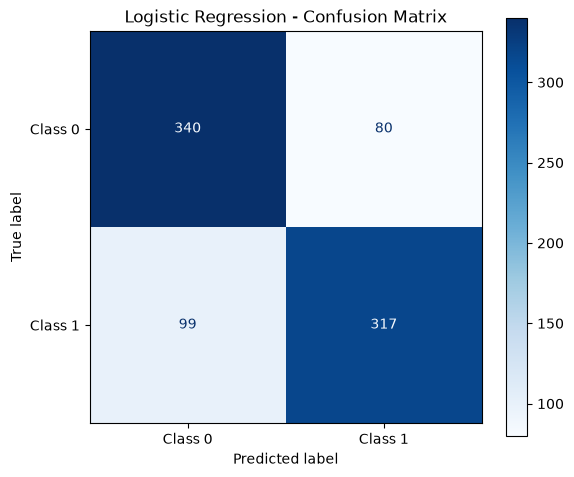

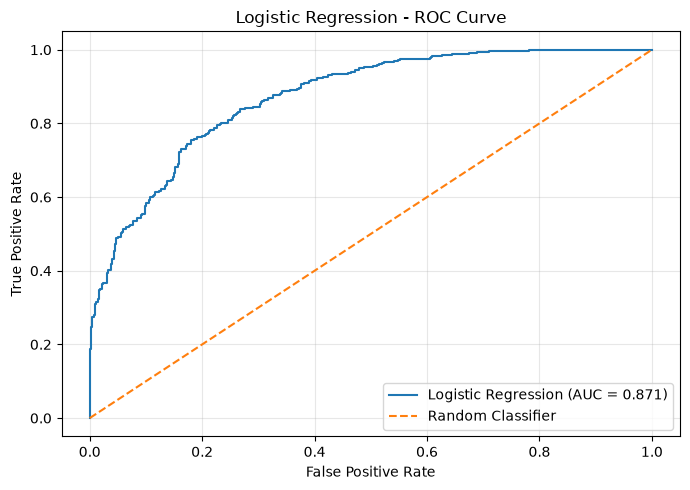

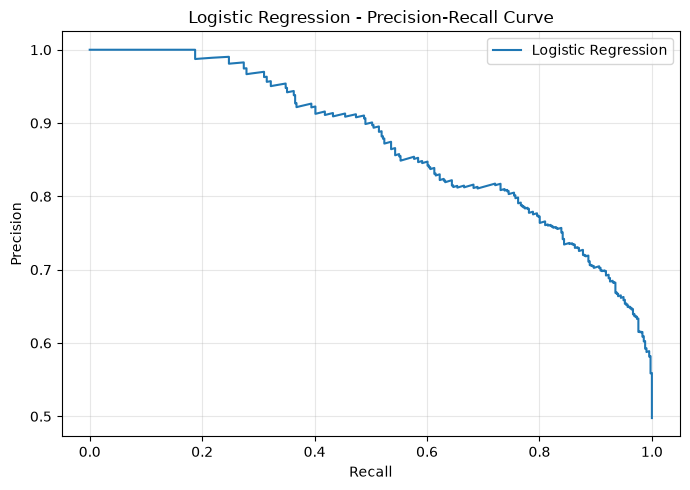

CLASSIFICATION PERFORMANCE
--------------------------
              precision    recall  f1-score   support

     Class 0       0.77      0.81      0.79       420
     Class 1       0.80      0.76      0.78       416

    accuracy                           0.79       836
   macro avg       0.79      0.79      0.79       836
weighted avg       0.79      0.79      0.79       836

Accuracy:  0.7859
Precision: 0.7985
Recall:    0.7620
F1 Score:  0.7798
ROC AUC:   0.8709


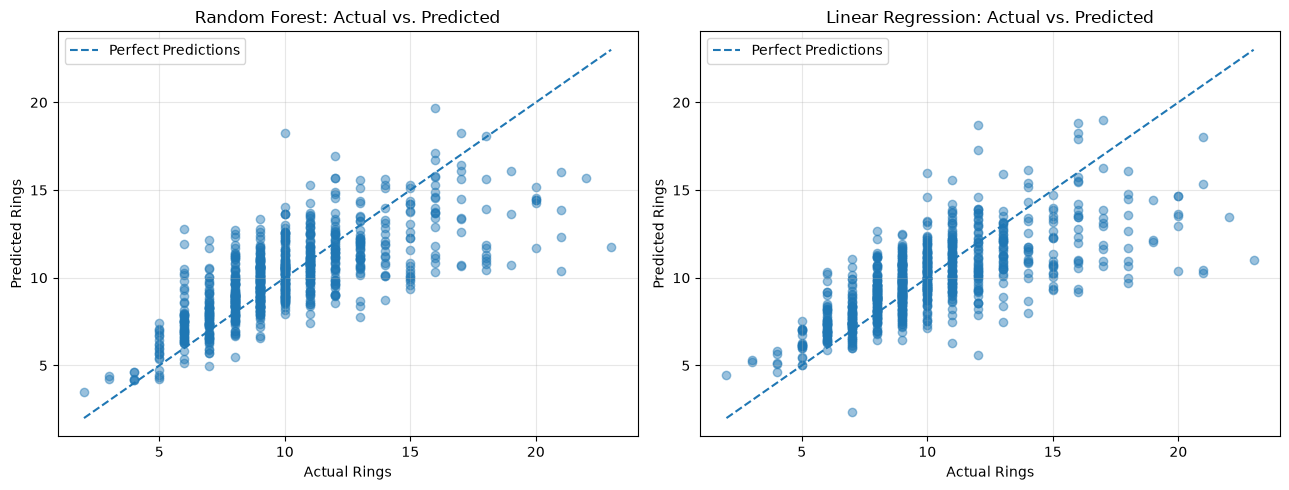

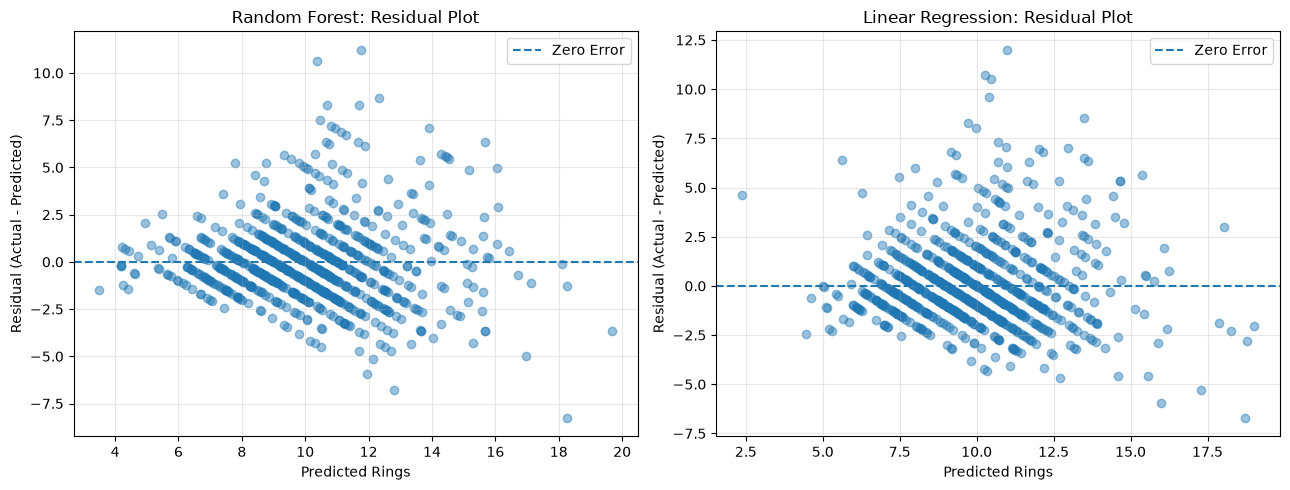

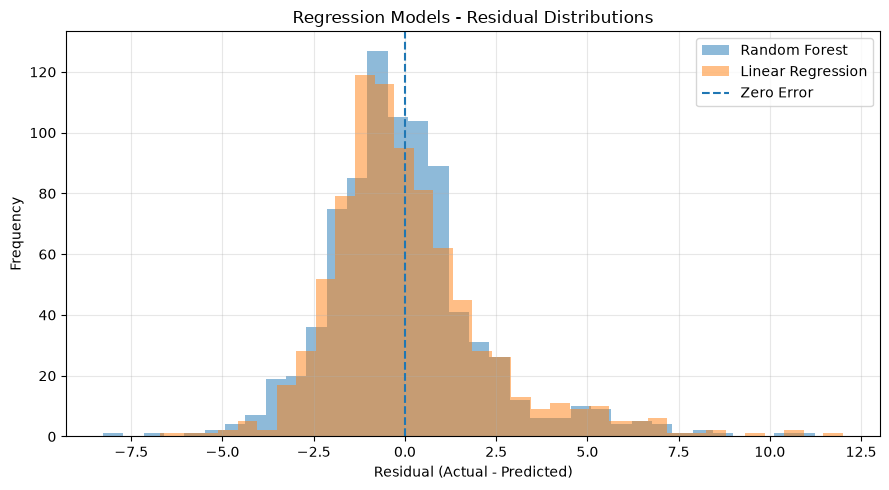

REGRESSION PERFORMANCE
----------------------
            Model    MAE    MSE   RMSE     R²
    Random Forest 1.5373 4.5949 2.1436 0.5229
Linear Regression 1.5846 4.8957 2.2126 0.4917


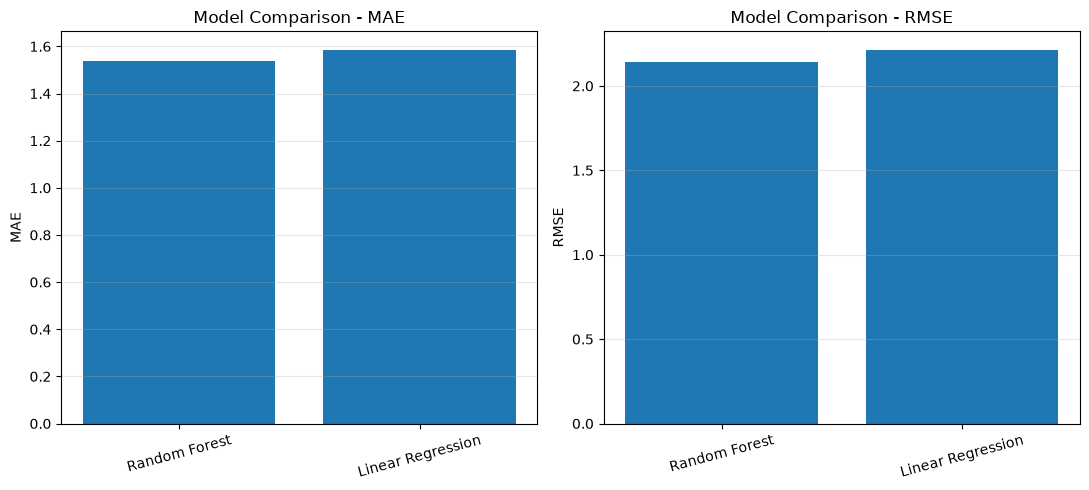

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load prediction results

classification_df = pd.read_csv("classification_predictions.csv")
regression_df = pd.read_csv("regression_predictions.csv")


# Classification: Confusion Matrix

y_true = classification_df["actual_class"]
y_pred = classification_df["logistic_pred_class"]
y_prob = classification_df["logistic_prob_class_1"]

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()


# 3. Classification: ROC Curve


fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 4. Classification: Precision-Recall Curve

precision, recall, thresholds = precision_recall_curve(
    y_true, y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(recall, precision, label="Logistic Regression")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 5. Classification: Performance Metrics

print("CLASSIFICATION PERFORMANCE")
print("--------------------------")

print(classification_report(
    y_true,
    y_pred,
    target_names=["Class 0", "Class 1"]
))

print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")


# Regression visualizations


actual = regression_df["actual_rings"]

regression_models = {
    "Random Forest": regression_df["random_forest_pred_rings"],
    "Linear Regression": regression_df["linear_regression_pred_rings"]
}


# 7. Regression: Actual vs. Predicted

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(
    axes, regression_models.items()
):
    ax.scatter(
        actual,
        predictions,
        alpha=0.45
    )

    # Perfect prediction reference line
    min_value = min(actual.min(), predictions.min())
    max_value = max(actual.max(), predictions.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        label="Perfect Predictions"
    )

    ax.set_xlabel("Actual Rings")
    ax.set_ylabel("Predicted Rings")
    ax.set_title(f"{model_name}: Actual vs. Predicted")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 8. Regression: Residual Plots

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(
    axes, regression_models.items()
):
    residuals = actual - predictions

    ax.scatter(
        predictions,
        residuals,
        alpha=0.45
    )

    ax.axhline(
        y=0,
        linestyle="--",
        label="Zero Error"
    )

    ax.set_xlabel("Predicted Rings")
    ax.set_ylabel("Residual (Actual - Predicted)")
    ax.set_title(f"{model_name}: Residual Plot")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 9. Regression: Residual Distributions

plt.figure(figsize=(9, 5))

for model_name, predictions in regression_models.items():
    residuals = actual - predictions

    plt.hist(
        residuals,
        bins=35,
        alpha=0.5,
        label=model_name
    )

plt.axvline(
    x=0,
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Regression Models - Residual Distributions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 10. Regression: Performance Metrics

regression_metrics = []

for model_name, predictions in regression_models.items():

    mae = mean_absolute_error(actual, predictions)
    mse = mean_squared_error(actual, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predictions)

    regression_metrics.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

regression_metrics_df = pd.DataFrame(regression_metrics)

print("REGRESSION PERFORMANCE")
print("----------------------")
print(regression_metrics_df.round(4).to_string(index=False))

# 11. Regression: Compare Error Metrics

metrics_to_plot = ["MAE", "RMSE"]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, metric in zip(axes, metrics_to_plot):

    ax.bar(
        regression_metrics_df["Model"],
        regression_metrics_df[metric]
    )

    ax.set_title(f"Model Comparison - {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
